In [1]:
# Parameters
name      = ""
fits_path = ""

In [2]:
# Parameters
name = "FLAMES-30Dor-6563-stellar"
fits_path = "fits_ready/FLAMES-30Dor-6563-stellar.fits"


In [3]:
import time
start_time=time.time()

In [4]:
import numpy as np
import seaborn as sns
import pandas as pd
import sys
from pathlib import Path
import astropy.units as u
from matplotlib import pyplot as plt
import corner
import json
from astropy.io import fits
from lmfit.model import save_modelresult


# Add path to py_modules 
sys.path.append(str(Path().resolve() / 'py_modules')) # 1 level up = project root

#import strucfunc                   
from strucfunc import sosflog
from strucfunc_mod import sosflogw
import fit_structure_function
import ci_results_compiler
import bfunc
import bplot
import list_maps_plots

# Velocity Field

In [5]:
from astropy.table import Table

data_in = Table.read("fits_ready/" + name + ".fits", hdu=1)
data_frame = data_in.to_pandas()

In [6]:
with fits.open("fits_ready/" + name + ".fits") as hdul:
    hdr = hdul[0].header

hdr

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                    8 / array data type                                
NAXIS   =                    0 / number of array dimensions                     
EXTEND  =                    T                                                  
FILE    = 'FLAMES-30Dor-6563'  / Fits file name                                 
NAME_ID = 'FLAMES-30Dor-H-X'   / pipeline identifier                            
REG     = 'NGC 2070'           / Region catalog name                            
NAME_REG= '30 Doradus'         / Region name                                    
REG_ID  = '30Dor   '           / Region identifier                              
TYPE_OBJ= 'H II region'        / Type object                                    
DIST    =                50000 / Distance in parsecs                            
INSTR   = 'FLAMES  '           / Instrument                                     
LINE    = 'H$\alpha$'       

In [7]:
#m3D      = hdul[0].header['M3D']
#ra       = hdul[0].header['RA']
sig      = hdul[0].header['SIG']
sig2     = hdul[0].header['SIG2']
s0       = hdul[0].header['S0']
#noise    = hdul[0].header['NOISE']
box_size = hdul[0].header['BOX_SIZE']
pc       = hdul[0].header['PC']
pix      = hdul[0].header['PIX']
line     = hdul[0].header['LINE']
binsize  = hdul[0].header['BINSIZE']

In [8]:
hdul.info()

Filename: fits_ready/FLAMES-30Dor-6563-stellar.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      22   ()      


C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\FLAMES_30dor\structure_function\one_component_revision\strucfunc_computation\py_modules\list_maps_plots.py:766: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 1, 0.96])


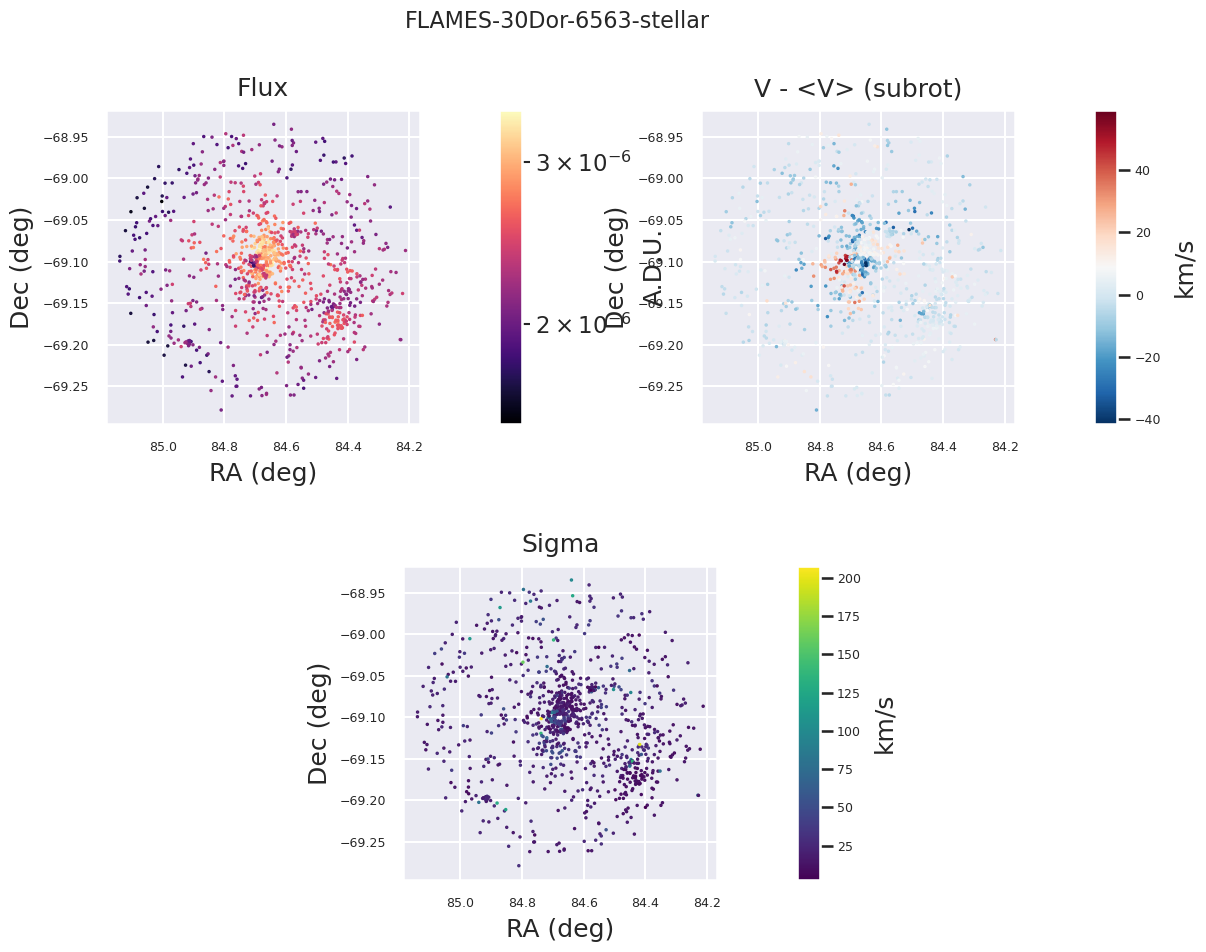

<Figure size 640x480 with 0 Axes>

In [9]:
fig, ax = list_maps_plots.plot_panels_norm(data_frame,
                                                s = 1.0,
                                                invert_ra=True,
                                                figsize=(14, 10),
                                                box_aspect=1.0,
                                                flux_normalization_value=1.710726e+06,
                                                figure_title = name)
plt.show()
plt.savefig('Imgs/' + name + '.jpg', bbox_inches='tight')

In [10]:
data_frame

,RAdeg,DEdeg,V_mean,log_F,sigma
0,84.659583,-69.040972,266.612024,4.251655,24.349696
1,84.618750,-69.075694,284.845399,4.243939,16.624635
2,84.358750,-69.124806,271.724316,3.733891,15.100781
3,84.825833,-69.146750,260.302065,3.826609,17.381412
4,84.977500,-69.111139,277.377279,3.763477,23.587322
...,...,...,...,...,...
983,85.043042,-69.051361,277.578023,3.475772,80.617613
984,85.138792,-69.093750,269.187516,3.022341,17.495122
985,84.365958,-69.134111,275.727772,3.998589,19.638368
986,84.640917,-69.076694,272.626021,4.810860,12.316174


# Structure function

In [11]:
#data_frame.columns=['X','Y','RV','I','Sig']
base_names = ['X', 'Y', 'RV', 'I', 'Sig']
data_frame.columns = base_names + list(data_frame.columns[5:])

In [12]:
#table = sosflog(data_frame, 0.05, 3600)
table = sosflogw(
    data_frame,
    dlog=0.05,
    c=3600,
    weight_col="I",
)

In [13]:
#s = 0.5 * (table[('s', 'min')] + table[('s', 'max')])*pc
#e_s = 0.5 * (table[('s', 'max')] - table[('s', 'min')])*pc
#b2 = table[('dV2', 'mean')]
#ng = table[('dV2', 'count')]
#e_b2 = table[('dV2', 'std')] / np.sqrt(ng)

In [14]:
ng = table[('dV2', 'count')]


# Separation in pc: c=3600 gives arcseconds; pc is pc/arcsec.
s = 0.5 * (table[("s", "min")] + table[("s", "max")]) * pc
e_s = 0.5 * (table[("s", "max")] - table[("s", "min")]) * pc

# Structure functions
b2 = table[("dV2", "mean")]
e_b2 = table[('dV2', 'std')] / np.sqrt(ng)


# Intensity-weighted structure function
b2w = table[("dV2", "weighted_mean")]
n_eff = table[("weights", "n_eff")]
std_w = table[("dV2", "weighted_std")]

# weighted_std uses population normalization.
# This correction recovers std / sqrt(N) when all weights are equal.
e_b2w = std_w / np.sqrt((n_eff - 1).where(n_eff > 1))

# Pair diagnostics
ng = table[("dV2", "count")]
sum_weights = table[("weights", "sum")]
n_eff = table[("weights", "n_eff")]

# Velocity variances calculated from the same accepted sample
sig2 = table.attrs["sigma2"]
sig2w = table.attrs["weighted_sigma2"]

In [15]:
#"Sum dv^2":
#"Sum weights":
#"Sum w * dv^2"
#"N pairs":
#"Weighted B(r)"

Br_results = {
    'log10 r'        : np.log10(s),
    'r'              : s,
    'r_err'          : e_s,
    "Unweighted B(r)": b2,
    'Unweighted B(r)_err' : e_b2,
    "Weighted B(r)": b2w,
    'Weighted B(r)_err' : e_b2w
}

Br_results_ = pd.DataFrame(Br_results)
Br = Br_results_ 

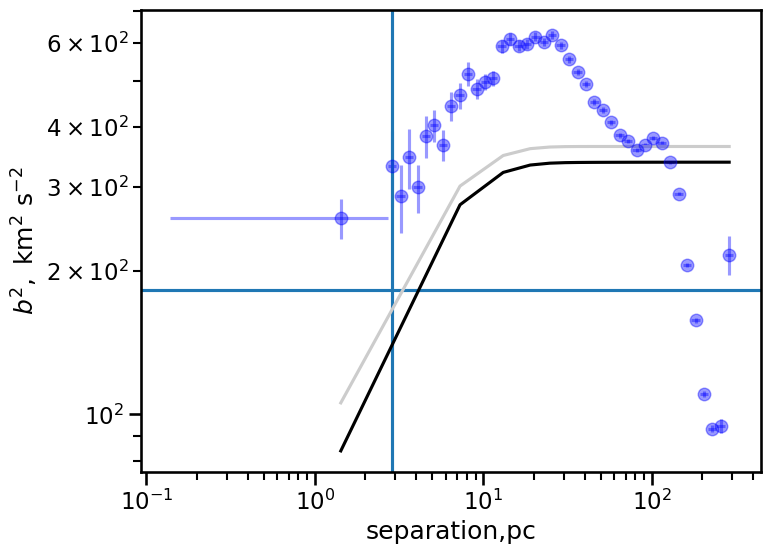

In [16]:
r0    = np.interp(sig2, b2[1:35], s[1:35])
ra = r0
m     = 1
noise = 0

rgrid = np.linspace(s.min(), s.max())

fig, ax = plt.subplots(figsize=(8, 6))

ax.errorbar(s, b2, yerr=e_b2, xerr=e_s, fmt='o', alpha=0.4,color="blue")

ax.axhline(sig2, ls='-')
ax.axvline(r0, ls='-')

ax.plot(rgrid, bfunc.bfunc00s(rgrid, r0, sig2, m), color="0.8")
ax.plot(rgrid, bfunc.bfunc03s(rgrid, r0, sig2, m, s0, noise), color="black")
#ax.plot(rgrid, bfunc.bfunc04s(rgrid, r0, sig2, m, s0, noise, box_size), color="black")


ax.set(xscale='log', yscale='log', 
       xlabel='separation,pc',
       ylabel=r'$b^2,\ \mathrm{km^2\ s^{-2}}$'
      )
None

plt.show()



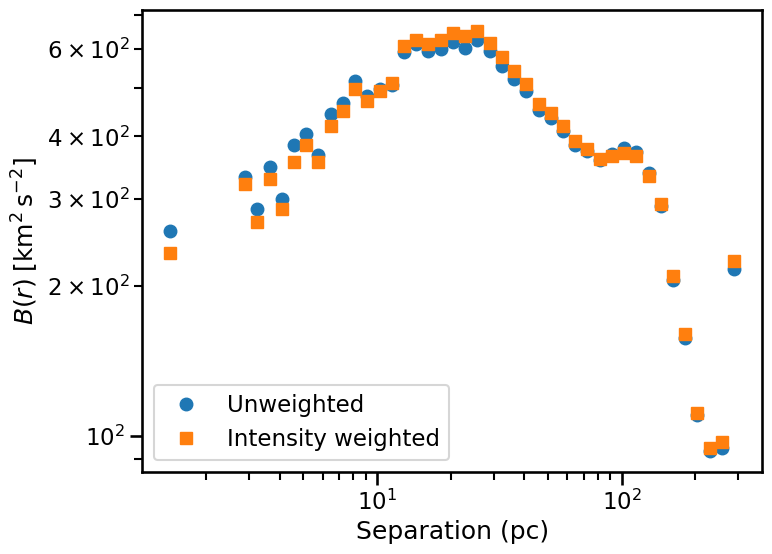

In [17]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(s, b2, "o", label="Unweighted")
ax.plot(s, b2w, "s", label="Intensity weighted")

ax.set(
    xscale="log",
    yscale="log",
    xlabel="Separation (pc)",
    ylabel=r"$B(r)\;[\mathrm{km^2\,s^{-2}}]$",
)
ax.legend()
plt.show()

# Export

In [18]:
df =  Br_results_.copy()

# Flatten MultiIndex columns like ('s','count') -> "s_count"
if isinstance(df.columns, pd.MultiIndex):
    df.columns = ["_".join(map(str, col)).strip() for col in df.columns.to_flat_index()]
else:
    df.columns = [str(c) for c in df.columns]

# (Optional) drop index to avoid it becoming an extra column
df = df.reset_index(drop=True)

t = Table.from_pandas(df)
new_hdu = fits.BinTableHDU(t, name="TABLE")

In [19]:
#with fits.open(fits_path, mode="readonly") as hdul:
#    hdus = [h.copy() for h in hdul]   # copy existing HDUs

#hdus.append(new_hdu)
#fits.HDUList(hdus).writeto(fits_path, overwrite=True)

In [20]:
with fits.open(fits_path, memmap=False) as hdul:
    hdus = [h.copy() for h in hdul]

# FITS EXTNAMEs are effectively case-insensitive; astropy reports them uppercase.
target = "TABLE"
idxs = [i for i, h in enumerate(hdus) if h.name.upper() == target]

if idxs:
    i0 = idxs[0]
    # Optional: preserve existing header cards (metadata) from old PARAMETERS
    old_hdr = hdus[i0].header.copy()
    hdus[i0] = new_hdu
    # Keep old metadata, then ensure EXTNAME stays correct
    hdus[i0].header.update(old_hdr)
    hdus[i0].name = target
    # Remove any additional duplicates if they exist
    for j in reversed(idxs[1:]):
        del hdus[j]
else:
    # If it doesn't exist, add it
    hdus.append(new_hdu)

fits.HDUList(hdus).writeto(fits_path, overwrite=True)

In [21]:
with fits.open(fits_path) as hdul:
    hdul.info()

Filename: fits_ready/FLAMES-30Dor-6563-stellar.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      22   ()      
  1  FLAMES-30DOR-6563    1 BinTableHDU     19   988R x 5C   [D, D, D, D, D]   
  2  TABLE         1 BinTableHDU     23   42R x 7C   [D, D, D, D, D, D, D]   


In [22]:
# Test import

from astropy.table import Table
t = Table.read(fits_path, hdu="TABLE")
df_loaded = t.to_pandas()


In [23]:
print("--- %s seconds ---" % (time.time()-start_time))

--- 7.071965217590332 seconds ---
